# CharacterGen: 정면 이미지 → 4방향 → 3D 메시

VS Code에서 CharacterGen 폴더를 작업 폴더로 열고 커널 **Python (CharacterGen)**을 선택한 뒤 셀을 위에서부터 실행하세요. 예제 입력은 이 프로젝트의 `test_inputs/kitty.png`이며, 다른 PNG를 테스트할 때는 입력 셀의 파일명만 바꾸면 됩니다. 결과는 `mv_res/notebook_test/<입력 파일명>/`에 저장됩니다.

**현재 PC 상태:** 전용 venv와 CUDA PyTorch는 준비됐지만, 3D 단계 필수 확장 `nvdiffrast`와 모델 가중치는 아직 없습니다. 다운로드 셀은 수 GB의 데이터를 받습니다. RTX 4050 6GB에서 추론 성공 여부도 미검증입니다. 이 노트북은 실제 모델을 호출하며 가짜 3D 결과를 만들지 않습니다.

In [1]:
from pathlib import Path
import os, sys, importlib.util
from IPython.display import display
from PIL import Image
import torch

ROOT = Path.cwd().resolve()
EXPECTED_PYTHON = ROOT / 'venv' / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
assert ROOT.joinpath('webui.py').is_file(), f'CharacterGen 폴더에서 노트북을 실행하세요. 현재 작업 폴더: {ROOT}'
assert Path(sys.executable).resolve() == EXPECTED_PYTHON.resolve(), (
    f'커널을 Python (CharacterGen)으로 바꾸세요. 현재: {sys.executable}'
)
assert torch.cuda.is_available(), 'CUDA GPU를 찾지 못했습니다.'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print('Python:', sys.executable)
print('GPU:', torch.cuda.get_device_name(0))
print('VRAM:', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), 'GiB')

Python: c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\venv\Scripts\python.exe
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
VRAM: 6.0 GiB


입력: C:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\2D_Stage\material\examples\1.png | 크기: (2444, 3200)


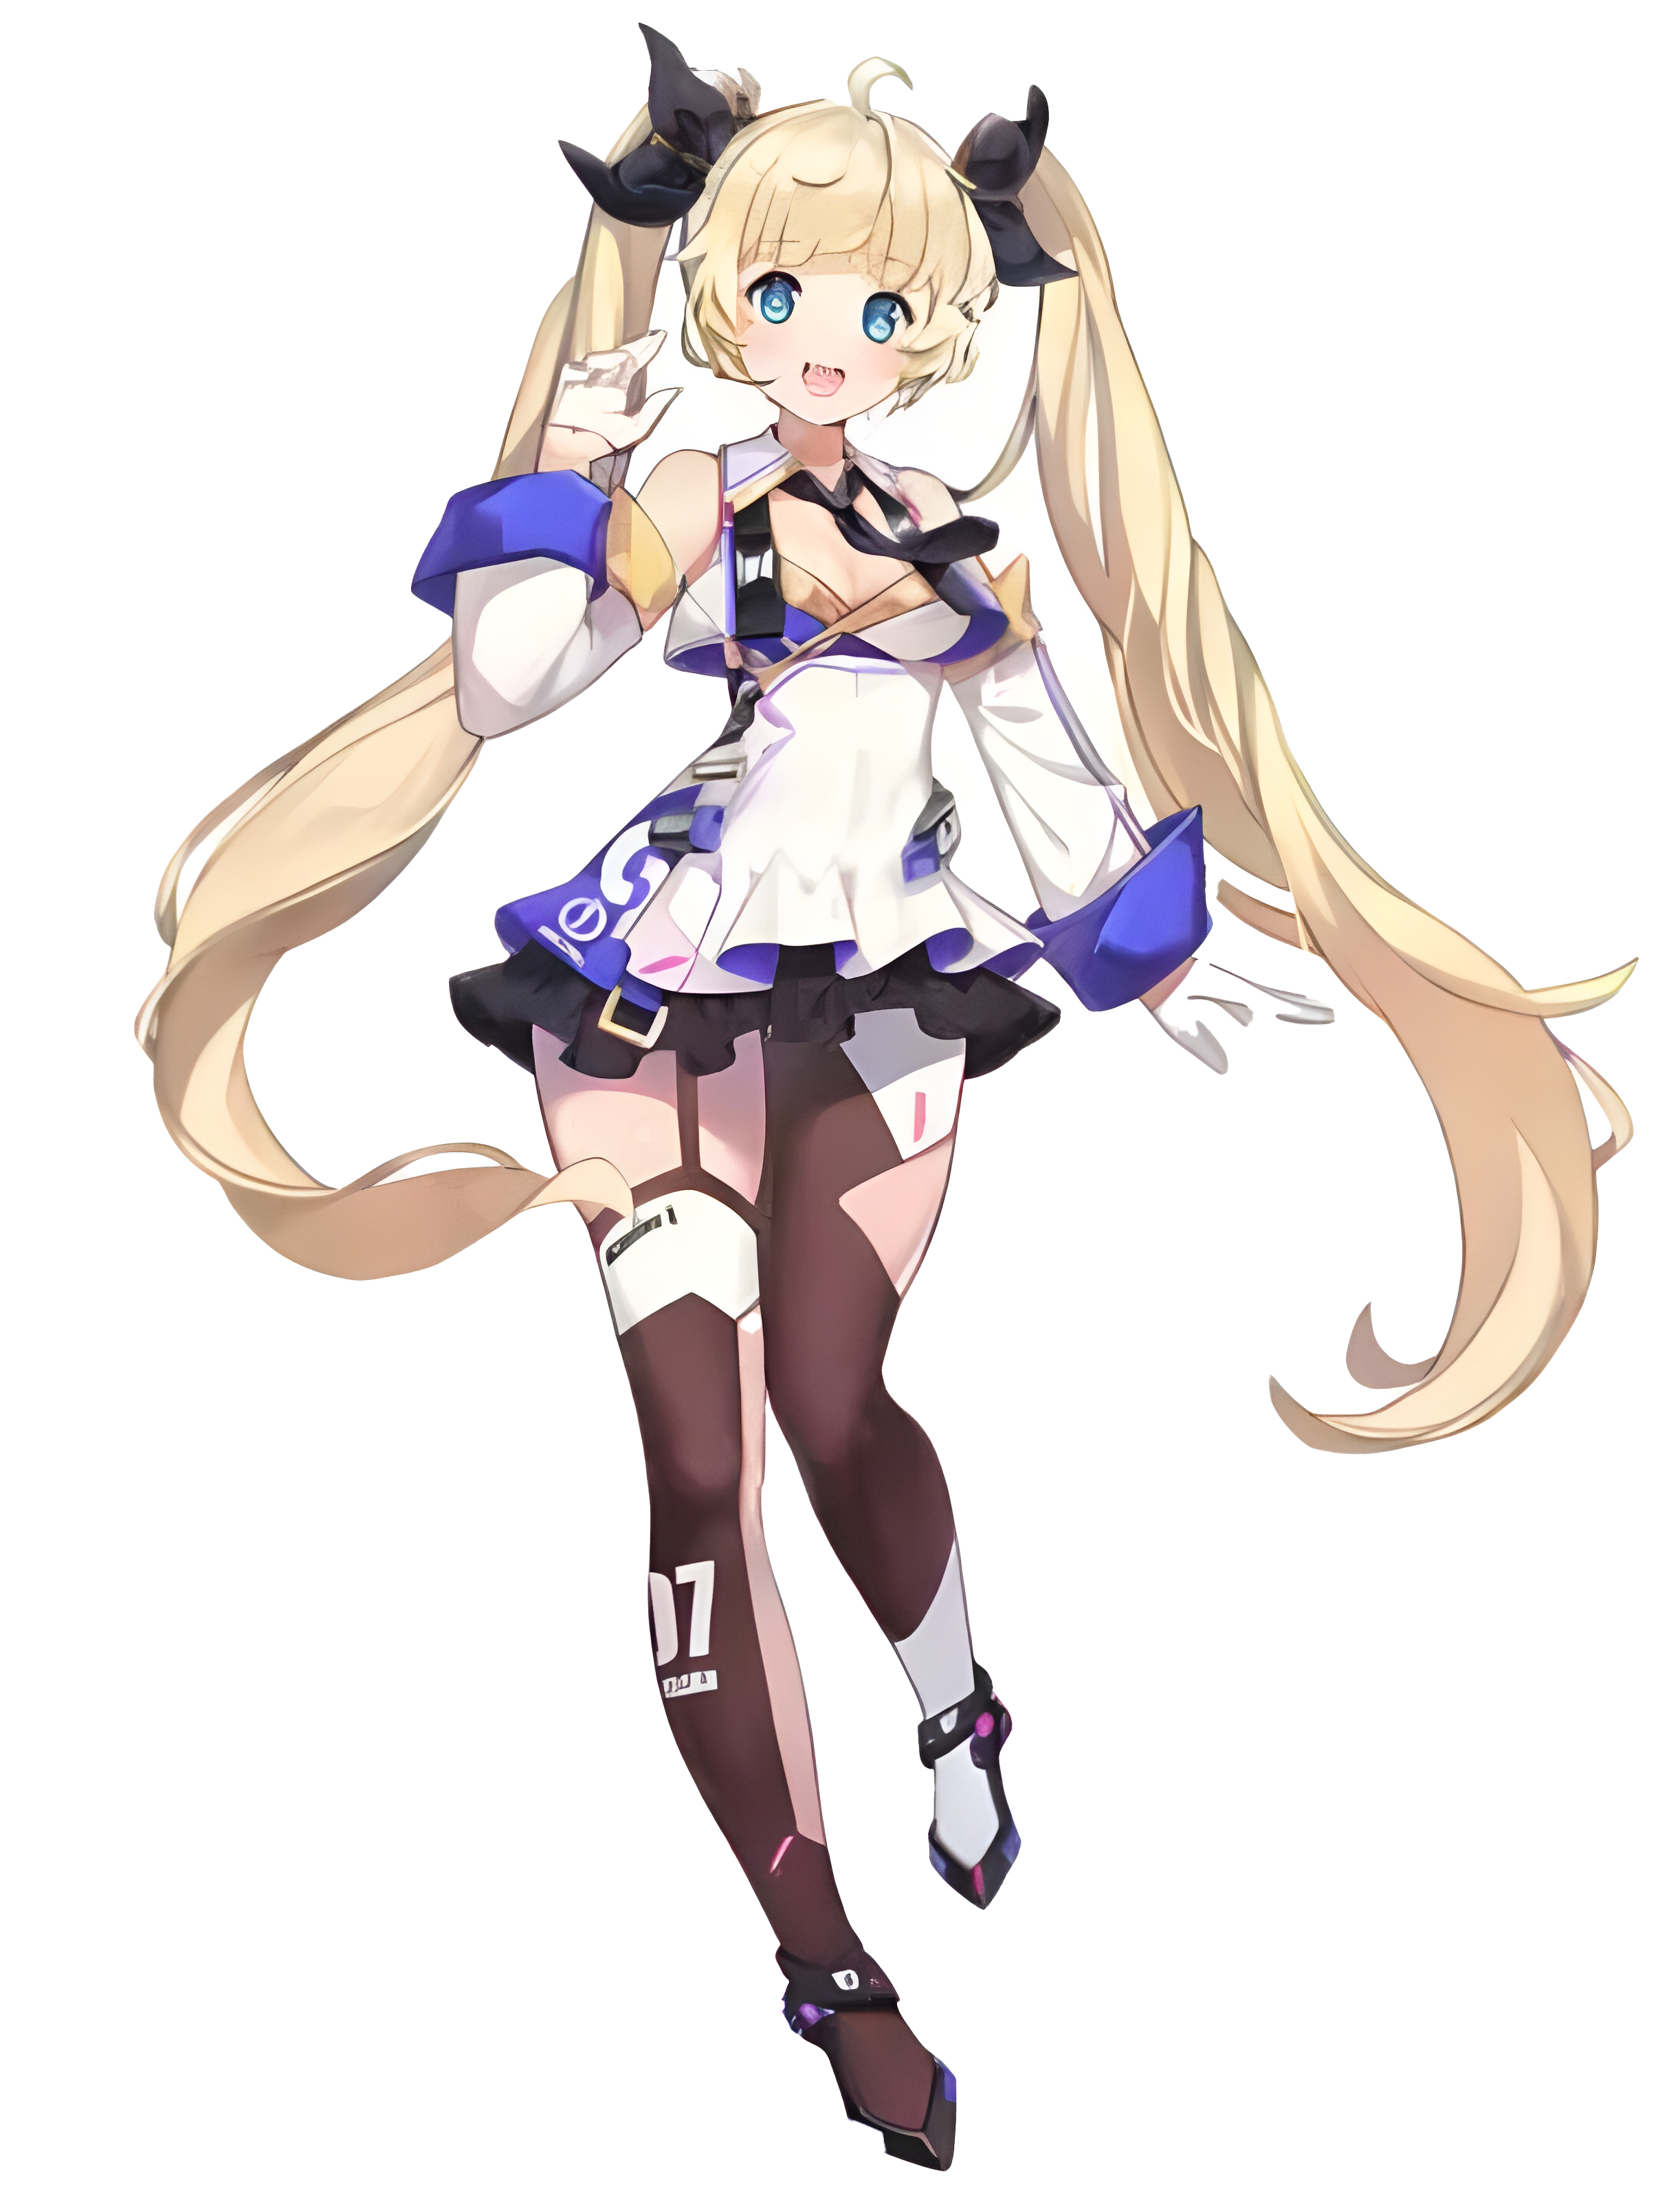

In [2]:
# test_inputs 폴더에 PNG를 넣고 파일명만 바꾸세요. 투명 배경의 전신 정면 PNG가 권장됩니다.
INPUT_PNG = ROOT / '2D_Stage' / 'material' / 'examples' / '1.png'
assert INPUT_PNG.is_file(), f'입력 이미지가 없습니다: {INPUT_PNG}'
input_image = Image.open(INPUT_PNG).convert('RGBA')
assert input_image.getbbox(), '입력 이미지가 완전히 투명합니다.'
print('입력:', INPUT_PNG, '| 크기:', input_image.size)
display(input_image)

## 1. 2D 가중치 다운로드

다음 셀은 CharacterGen 2D 가중치를 내려받습니다(공식 저장소의 2D 모델 폴더 약 9.5GB). 2D 추론 시 Stable Diffusion 2.1도 Hugging Face에서 추가로 받아야 합니다. 처음 한 번만 실행하세요.

In [3]:
from huggingface_hub import snapshot_download
snapshot_download(
    repo_id='zjpshadow/CharacterGen',
    allow_patterns=['2D_Stage/models/*'],
    local_dir=str(ROOT),
    max_workers=2,
)
assert (ROOT / '2D_Stage' / 'models' / 'checkpoint' / 'pytorch_model.bin').is_file()
print('2D 가중치 준비 완료')

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

2D 가중치 준비 완료


## 2. 4방향 이미지 생성

공식 `Inference2D_API`를 그대로 사용합니다. 6GB VRAM에서 메모리 부족이 나면 이 노트북 문제가 아니라 실행 자원 한계일 수 있습니다. 이 경우 더 큰 GPU에서 같은 노트북을 실행해야 합니다.

In [4]:
from omegaconf import OmegaConf
import webui as cg

cfg2d = OmegaConf.load(ROOT / '2D_Stage' / 'configs' / 'infer.yaml')
infer2d = cg.Inference2D_API(**cfg2d)
raw_views = infer2d.inference(input_image, val_width=512, val_height=768, crop=True, seed=2333, timestep=40)
assert len(raw_views) == 4
print('4방향 이미지 생성 완료')

c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\venv\lib\site-packages\transformers\utils\generic.py:260: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  torch.utils._pytree._register_pytree_node(
c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\venv\lib\site-packages\xformers\ops\fmha\flash.py:211: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flash::flash_fwd")
c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\venv\lib\site-packages\xformers\ops\fmha\flash.py:344: FutureWarning: `torch.library.impl_abstract` was renamed to `torch.library.register_fake`. Please use that instead; we will remove `torch.library.impl_abstract` in a future version of PyTorch.
  @torch.library.impl_abstract("xformers_flas

CUDA device capability is above 8, using bfloat16.


c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\venv\lib\site-packages\huggingface_hub\file_download.py:1142: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
c:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\venv\lib\site-packages\transformers\modeling_utils.py:479: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mod

4방향 이미지 생성 완료


**front**

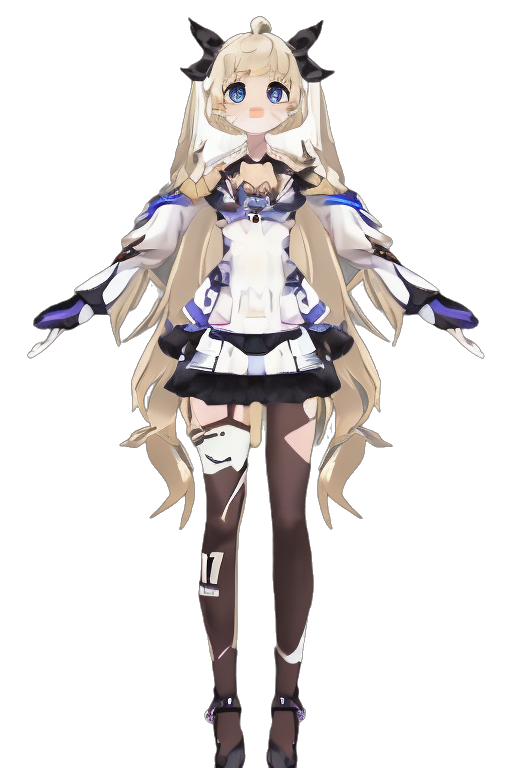

**right**

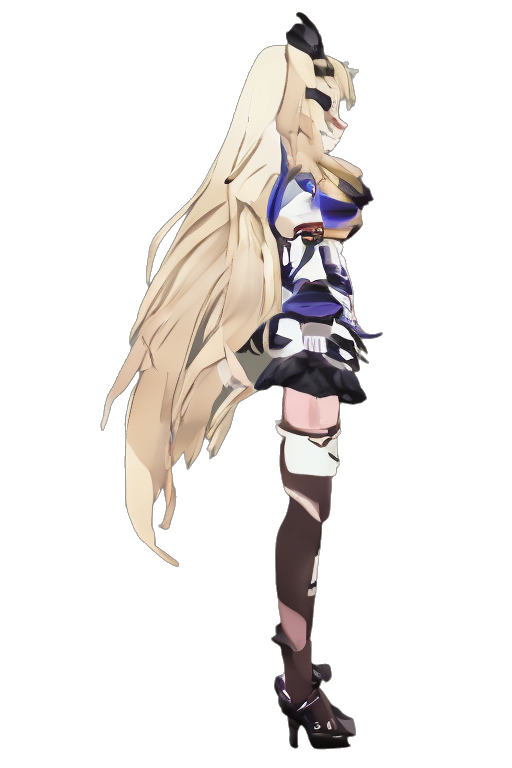

**back**

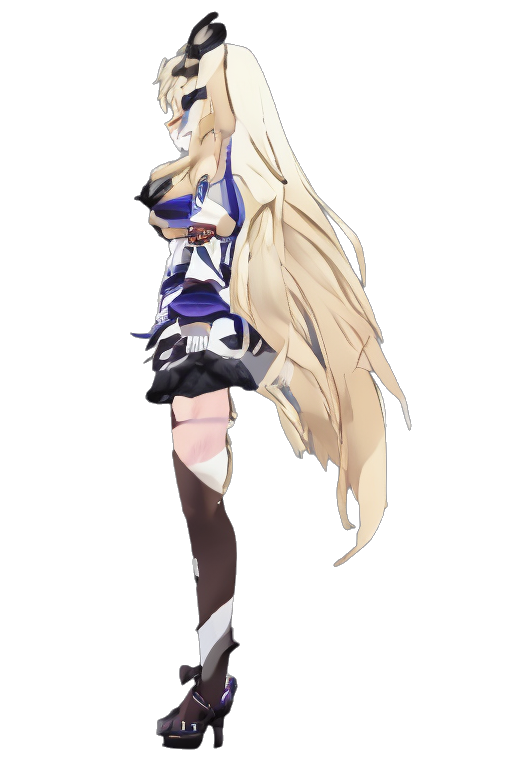

**left**

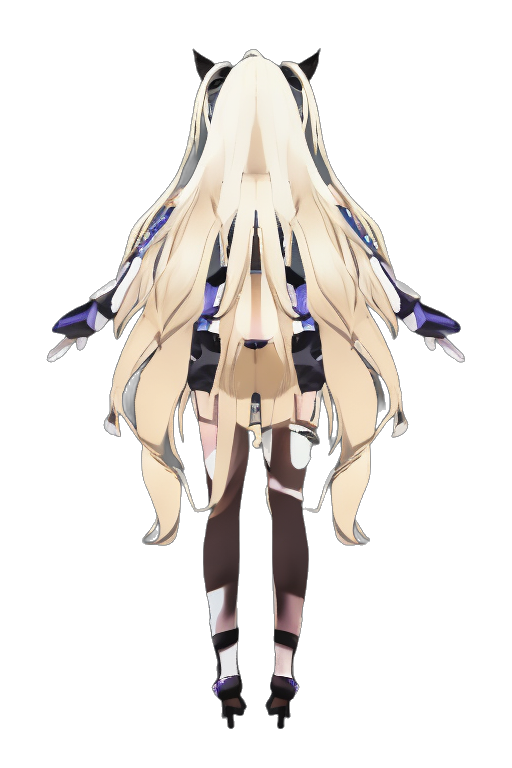

2D 결과: C:\Users\SSAFY\Desktop\자율플젝 아이디어\3D 실험용\CharacterGen\mv_res\notebook_test\1


In [5]:
from IPython.display import Markdown

# 공식 통합 UI의 출력 순서: 오른쪽, 뒤, 왼쪽, 앞
segmenter = cg.rm_bg_api(force_cpu=True)
right, back, left, front = segmenter.remove_background(raw_views, alpha_min=0.2, alpha_max=0.9)
SCENE_DIR = ROOT / 'mv_res' / 'notebook_test' / INPUT_PNG.stem
SCENE_DIR.mkdir(parents=True, exist_ok=True)
views = {'front': front, 'right': right, 'back': back, 'left': left}
for name, image in views.items():
    image.save(SCENE_DIR / f'{name}.png')
    display(Markdown(f'**{name}**'))
    display(image)
print('2D 결과:', SCENE_DIR)

In [5]:
'''
for i, view in enumerate(raw_views):
    print(i)
    display(view)
'''

'\nfor i, view in enumerate(raw_views):\n    print(i)\n    display(view)\n'

## 3. 3D 메시 생성

아래 셀은 **실제 3D 메시**를 만드는 공식 3D 단계를 사용합니다. 현재 Windows 환경은 `nvdiffrast` 빌드에 필요한 CUDA Toolkit/Visual Studio C++ Build Tools가 없어 여기서 멈춥니다. 개발 도구를 준비해 `nvdiffrast` 설치를 마친 뒤 다시 실행하세요. 3D 가중치 다운로드는 선행조건 검사 뒤에 시작합니다.

In [ ]:
if importlib.util.find_spec('nvdiffrast') is None:
    raise RuntimeError('3D 단계 필수 패키지 nvdiffrast가 없습니다. LOCAL_SETUP_STATUS.md의 차단 원인을 확인하세요.')
import gc
del infer2d
gc.collect()

torch.cuda.empty_cache()
snapshot_download(
    repo_id='zjpshadow/CharacterGen',
    allow_patterns=['3D_Stage/models/*'],
    local_dir=str(ROOT),
    max_workers=2,
)
assert (ROOT / '3D_Stage' / 'models' / 'lrm.ckpt').is_file()
print('3D 가중치 준비 완료')

In [ ]:
import shutil

infer3d = cg.Inference3D_API()
save_dir, obj_path, glb_path = infer3d.process_images(
    back, front, right, left, back_proj=False, smooth_iter=5
)
# 공식 코드가 만든 전체 결과(텍스처 등 포함)를 입력 이미지별 결과 폴더에도 보관합니다.
MESH_DIR = SCENE_DIR / '3d' / Path(save_dir).name
shutil.copytree(save_dir, MESH_DIR, dirs_exist_ok=True)
obj_path = MESH_DIR / Path(obj_path).name
glb_path = MESH_DIR / Path(glb_path).name
print('3D 결과 폴더:', MESH_DIR.resolve())
print('OBJ:', obj_path.resolve())
print('GLB:', glb_path.resolve())

In [ ]:
import trimesh
from IPython.display import FileLink
mesh = trimesh.load(glb_path, force='scene')
print('3D 장면 경계 크기 (x, y, z):', mesh.extents)
display(FileLink(Path(glb_path).resolve()))
print('GLB 파일을 Blender에 열어 옆면과 뒷면의 실제 부피를 확인하세요.')